# Lab 1 — Intro to Behavioral TV Data
Name: Daryna Koval | Group: KM-42

## Setup

In [2]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/2")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")

100%|██████████| 5.90M/5.90M [00:00<00:00, 129MB/s]

Extracting files...


## Task 1.1 — Panel and universe

In [3]:
programs["broadcast_date"] = pd.to_datetime(programs["broadcast_date"])
daily_weights["broadcast_date"] = pd.to_datetime(daily_weights["broadcast_date"])
hh = daily_weights[daily_weights["resp_type"] == "H"]
pers = daily_weights[daily_weights["resp_type"] != "H"]
hh_day = hh.groupby("broadcast_date")["weight"].agg(["count", "sum"])
pers_day = pers.groupby("broadcast_date")["weight"].agg(["count", "sum"])

print("Telecasts:", programs["telecast_id"].nunique())
print("Programs:", programs["program_name"].nunique())
print("Networks:", programs["network_code"].nunique())
print("Households in panel:", hh["respondent_id"].nunique())
print("Persons in panel:", pers["respondent_id"].nunique())
print("Households in-tab, average day:", round(hh_day["count"].mean()))
print("Persons in-tab, average day:", round(pers_day["count"].mean()))
print("US TV households represented, average day (M):", f"{hh_day['sum'].mean() / 1e6:.2f}")
print("US persons represented, average day (M):", f"{pers_day['sum'].mean() / 1e6:.2f}")
extra = set(viewer_attributes["respondent_id"]) - set(daily_weights["respondent_id"])
print("In viewer_attributes but never in-tab:", len(extra))
print("  of them households:", sum(i % 100 == 0 for i in extra))
print("  their viewing rows:", viewings["respondent_id"].isin(extra).sum())

Telecasts: 5841
Programs: 246
Networks: 10
Households in panel: 4254
Persons in panel: 10210
Households in-tab, average day: 3878
Persons in-tab, average day: 9269
US TV households represented, average day (M): 125.80
US persons represented, average day (M): 317.28
In viewer_attributes but never in-tab: 8
  of them households: 2
  their viewing rows: 0


**Answer:** viewer_attributes lists a few more (8 more ids: 2 households and 6 persons) because they are in the panel
but were never in-tab in October (no daily weight and no viewing). On an average day 3,878 households and 9,269 persons are in-tab, and their weights add up
to the whole US: 125.80 M TV households and 317.28 M persons.

## Task 1.2 — Average audience by hour of day

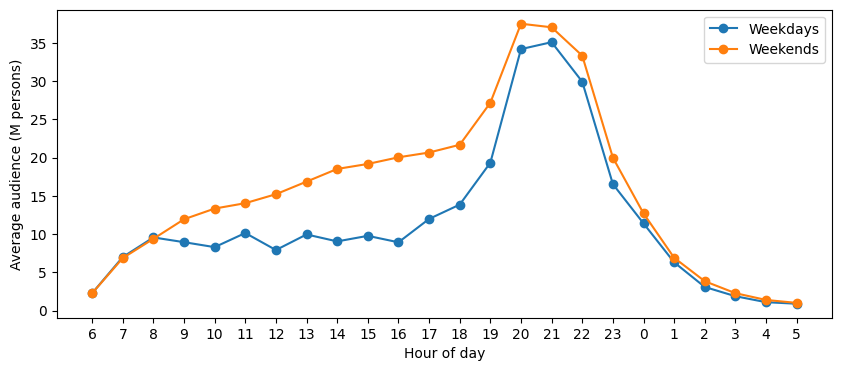

Peak hour, weekdays: 21
Peak hour, weekends: 20
Daytime average 9-17 (M), weekdays: 9.11
Daytime average 9-17 (M), weekends: 16.13


In [4]:
v = viewings[viewings["resp_type"].isin(["R", "L"])].copy()
v["minutes"] = (v["end_ts"] - v["start_ts"]).dt.total_seconds() // 60
m = v.loc[v.index.repeat(v["minutes"]), ["start_ts", "weight"]]
m["ts"] = m["start_ts"] + pd.to_timedelta(m.groupby(level=0).cumcount(), unit="min")
m["hour"] = m["ts"].dt.hour
m["bday"] = (m["ts"] - pd.Timedelta(hours=6)).dt.normalize()
m["weekend"] = m["bday"].dt.dayofweek >= 5

days = pd.Series(daily_weights["broadcast_date"].unique())
n_weekend = (days.dt.dayofweek >= 5).sum()
n_weekday = len(days) - n_weekend
by_hour = m.groupby(["weekend", "hour"])["weight"].sum()
weekday = by_hour[False] / 60 / n_weekday / 1e6
weekend = by_hour[True] / 60 / n_weekend / 1e6

hours = list(range(6, 24)) + list(range(0, 6))
plt.figure(figsize=(10, 4))
plt.plot([str(h) for h in hours], weekday[hours], marker="o", label="Weekdays")
plt.plot([str(h) for h in hours], weekend[hours], marker="o", label="Weekends")
plt.xlabel("Hour of day")
plt.ylabel("Average audience (M persons)")
plt.legend()
plt.show()

print("Peak hour, weekdays:", weekday.idxmax())
print("Peak hour, weekends:", weekend.idxmax())
day = list(range(9, 17))
print("Daytime average 9-17 (M), weekdays:", round(weekday[day].mean(), 2))
print("Daytime average 9-17 (M), weekends:", round(weekend[day].mean(), 2))

**Answer:** The peak is in prime time on both: 21:00 on weekdays and 20:00 on weekends (one hour earlier).
In the daytime (9-17) the weekend audience is about 1.8 times bigger: 16.1 M vs 9.1 M on weekdays, because people
are not at work and there is football.

## Task 1.3 — Session length

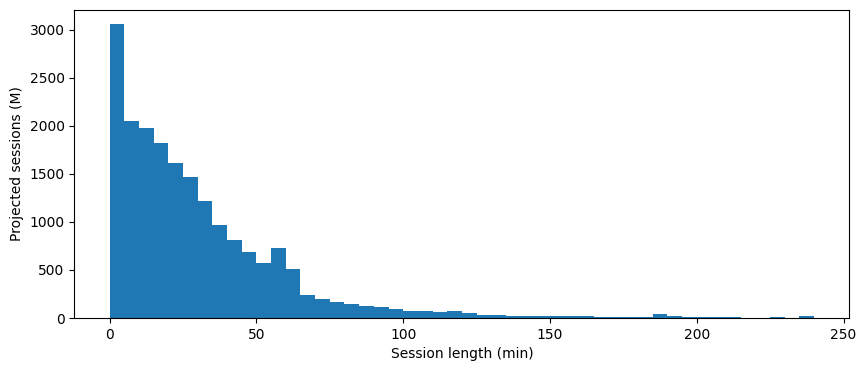

Session length, weighted mean (min): 29.4
Session length, weighted median (min): 21


In [5]:
total_w = v["weight"].sum()
mean_len = (v["minutes"] * v["weight"]).sum() / total_w
s = v.sort_values("minutes")
cum_w = s["weight"].cumsum()
median_len = int(s[cum_w >= total_w / 2]["minutes"].iloc[0])
plt.figure(figsize=(10, 4))
plt.hist(v["minutes"].clip(upper=240), bins=range(0, 245, 5), weights=v["weight"] / 1e6)
plt.xlabel("Session length (min)")
plt.ylabel("Projected sessions (M)")
plt.show()

print("Session length, weighted mean (min):", round(mean_len, 1))
print("Session length, weighted median (min):", median_len)

**Answer:** Most sessions are short, but a few are very long (a game or a whole evening on one channel),
and they pull the mean up. The median is not affected by them, so I would show the median to a client:
a typical session is about 21 minutes. (The last bar of the histogram is all sessions of 240+ minutes.)

## Task 2 — Program reach curve

                HH rating (%)  P2+ rating (%)  Audience (M)
broadcast_date                                             
2024-10-01                3.5             1.7          5.28
2024-10-02                3.1             1.5          4.68
2024-10-03                3.0             1.5          4.68
2024-10-04                3.0             1.5          4.81
2024-10-07                3.1             1.5          4.83
2024-10-08                3.2             1.6          4.97
2024-10-09                3.0             1.5          4.70
2024-10-10                3.4             1.6          5.13
2024-10-11                3.1             1.5          4.69
2024-10-14                2.9             1.4          4.59
2024-10-15                3.1             1.5          4.82
2024-10-16                3.0             1.5          4.62
2024-10-17                3.4             1.7          5.30
2024-10-18                2.7             1.3          4.23
2024-10-21                3.1           

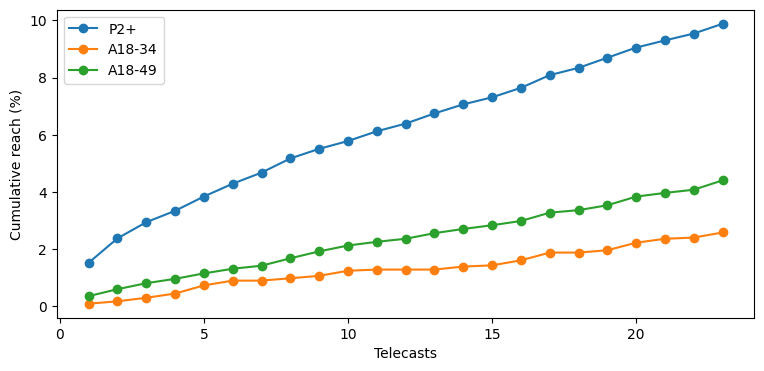

Telecasts of the program: 23
Average household rating (%): 3.2
Average P2+ rating (%): 1.6
Average projected audience (M): 4.93
Final reach P2+ (%): 9.9
Final reach A18-34 (%): 2.6
Final reach A18-49 (%): 4.4
Final reach A50+ (%): 19.1


In [6]:
news = programs[programs["program_name"] == "CBS Evening News"].sort_values("start_ts")
news = news[["telecast_id", "broadcast_date", "start_ts", "end_ts"]]
news["n"] = range(1, len(news) + 1)

cbs = viewings[viewings["network_code"] == "CBS"].copy()
cbs["broadcast_date"] = (cbs["start_ts"] - pd.Timedelta(hours=6)).dt.normalize()
x = cbs.merge(news, on="broadcast_date", suffixes=("", "_tc"))
overlap = x[["end_ts", "end_ts_tc"]].min(axis=1) - x[["start_ts", "start_ts_tc"]].max(axis=1)
x = x[overlap >= pd.Timedelta(minutes=1)]
watched = x.drop_duplicates(["telecast_id", "respondent_id"])

hh_w = watched[watched["resp_type"] == "H"].groupby("telecast_id")["weight"].sum()
p_w = watched[watched["resp_type"].isin(["R", "L"])].groupby("telecast_id")["weight"].sum()
table = news.set_index("telecast_id")
table["HH rating (%)"] = hh_w / table["broadcast_date"].map(hh_day["sum"]) * 100
table["P2+ rating (%)"] = p_w / table["broadcast_date"].map(pers_day["sum"]) * 100
table["Audience (M)"] = p_w / 1e6
print(table.set_index("broadcast_date")[["HH rating (%)", "P2+ rating (%)", "Audience (M)"]].round({"HH rating (%)": 1, "P2+ rating (%)": 1, "Audience (M)": 2}))

va = viewer_attributes.merge(attributes, on="attr_id")
age = va[va["attr_name"] == "Age in years"].set_index("respondent_id")["value"]

month_w = pers.groupby("respondent_id")["weight"].mean()
pp = pd.DataFrame({"w": month_w, "age": age[month_w.index]})
groups = {
    "P2+": pp,
    "A18-34": pp[(pp["age"] >= 18) & (pp["age"] <= 34)],
    "A18-49": pp[(pp["age"] >= 18) & (pp["age"] <= 49)],
}

pw = watched[watched["resp_type"].isin(["R", "L"])]
first = pw.groupby("respondent_id")["n"].min()

reach = pd.DataFrame(index=news["n"])
for name, g in groups.items():
    f = first[first.index.isin(g.index)]
    new_w = g.loc[f.index, "w"].groupby(f).sum().reindex(news["n"], fill_value=0)
    reach[name] = new_w.cumsum() / g["w"].sum() * 100

reach.plot(marker="o", figsize=(9, 4))
plt.xlabel("Telecasts")
plt.ylabel("Cumulative reach (%)")
plt.show()

print("Telecasts of the program:", len(news))
print("Average household rating (%):", round(table["HH rating (%)"].mean(), 1))
print("Average P2+ rating (%):", round(table["P2+ rating (%)"].mean(), 1))
print("Average projected audience (M):", f"{table['Audience (M)'].mean():.2f}")
print("Final reach P2+ (%):", round(reach["P2+"].iloc[-1], 1))
print("Final reach A18-34 (%):", round(reach["A18-34"].iloc[-1], 1))
print("Final reach A18-49 (%):", round(reach["A18-49"].iloc[-1], 1))
a50 = pp[pp["age"] >= 50]
print("Final reach A50+ (%):", round(a50.loc[a50.index.isin(first.index), "w"].sum() / a50["w"].sum() * 100, 1))

**Answer:** A rating counts the viewers of one telecast, and mostly the same people watch every day, so it
stays about the same (P2+ about 1.3-1.8%). Reach counts each person only once, and every new telecast brings
some new people, so it keeps growing, but more and more slowly, because most viewers are already counted.
Of the three audiences the program reaches P2+ best (9.9%), much more than A18-34 (2.6%) and A18-49 (4.4%).
So most of its viewers are older: reach for A50+ is 19.1%, twice the P2+ reach. This matches what we know: evening news is watched
mostly by older people.

## Task 3 — Program frequency

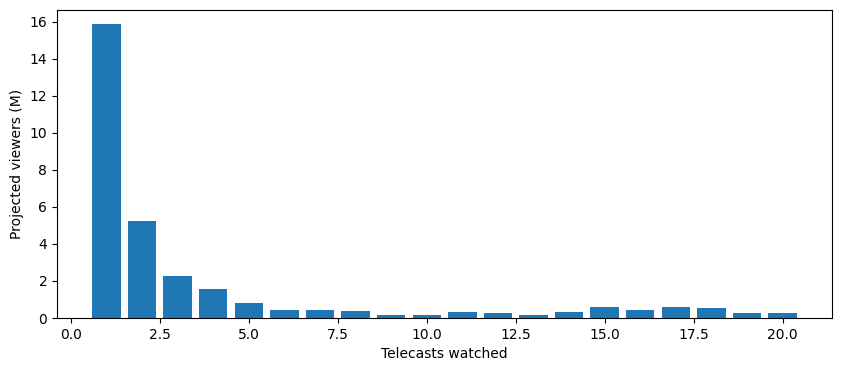

Projected viewers (M): 30.80
Average frequency (weighted): 3.6
Median frequency (weighted): 1
Share of views from the most loyal viewers: 0.704
Loyal viewers: frequency at least 4
Share of viewers who are loyal: 0.243


In [7]:
yr = programs[programs["program_name"] == "The Young and the Restless"]
yr = yr[["telecast_id", "broadcast_date", "start_ts", "end_ts"]]
x = cbs[cbs["resp_type"].isin(["R", "L"])].merge(yr, on="broadcast_date", suffixes=("", "_tc"))
overlap = x[["end_ts", "end_ts_tc"]].min(axis=1) - x[["start_ts", "start_ts_tc"]].max(axis=1)
x = x[overlap >= pd.Timedelta(minutes=1)]

freq = x.groupby("respondent_id")["telecast_id"].nunique()
fv = pd.DataFrame({"freq": freq, "w": month_w[freq.index]}).sort_values("freq")
total_w = fv["w"].sum()
cum_w = fv["w"].cumsum()

avg_freq = (fv["freq"] * fv["w"]).sum() / total_w
median_freq = fv[cum_w >= total_w / 2]["freq"].iloc[0]
p80 = fv[cum_w >= total_w * 0.8]["freq"].iloc[0]
views = fv["freq"] * fv["w"]
loyal_share = views[fv["freq"] >= p80].sum() / views.sum()

dist = fv.groupby("freq")["w"].sum() / 1e6
plt.figure(figsize=(10, 4))
plt.bar(dist.index, dist.values)
plt.xlabel("Telecasts watched")
plt.ylabel("Projected viewers (M)")
plt.show()

print("Projected viewers (M):", f"{total_w / 1e6:.2f}")
print("Average frequency (weighted):", round(avg_freq, 1))
print("Median frequency (weighted):", median_freq)
print("Share of views from the most loyal viewers:", f"{loyal_share:.3f}")
print("Loyal viewers: frequency at least", p80)
print("Share of viewers who are loyal:", f"{fv.loc[fv['freq'] >= p80, 'w'].sum() / total_w:.3f}")

**Answer:** No. The average is about 3.6, but the median is 1: at least half of the viewers saw only one
episode. The loyal viewers (4 or more episodes) are only 24.3% of all viewers, but they give 70.4% of all
views. The average mixes these two groups and describes neither of them.

## Task 4 — Networks by age and gender

In [8]:
sex = va[va["attr_group"] == "Sex"].set_index("respondent_id")["attr_name"]
vp = v.copy()
vp["age"] = vp["respondent_id"].map(age)
vp["sex"] = vp["respondent_id"].map(sex).map({"Male": "M", "Female": "W"})
vp["proj_min"] = vp["minutes"] * vp["weight"]
vp["age_group"] = None
vp.loc[(vp["age"] >= 18) & (vp["age"] <= 34), "age_group"] = "18-34"
vp.loc[(vp["age"] >= 35) & (vp["age"] <= 54), "age_group"] = "35-54"
vp.loc[vp["age"] >= 55, "age_group"] = "55+"
vp["audience"] = vp["sex"] + vp["age_group"]

mins = vp.groupby(["network_code", "audience"])["proj_min"].sum().unstack() / 1e6
for aud in ["M18-34", "W18-34", "M35-54", "W35-54", "M55+", "W55+"]:
    print(aud, "(M projected minutes)")
    print(mins[aud].sort_values(ascending=False).head(5).round(1))
    print()

young = vp["age_group"] == "18-34"
share = pd.DataFrame({
    "weighted": vp[young].groupby("network_code")["proj_min"].sum() / vp.groupby("network_code")["proj_min"].sum(),
    "raw": vp[young].groupby("network_code")["minutes"].sum() / vp.groupby("network_code")["minutes"].sum(),
}).sort_values("weighted", ascending=False)

print(share.round(3))
print("Youngest network:", share["weighted"].idxmax())
print("Oldest network:", share["weighted"].idxmin())
print()
print("18-34 projected minutes (M) by network:")
print((vp[young].groupby("network_code")["proj_min"].sum() / 1e6).sort_values(ascending=False).round(1))

M18-34 (M projected minutes)
network_code
FOX    4386.6
NBC    3910.4
CBS    3044.3
ABC    3010.8
FX     1474.0
Name: M18-34, dtype: float64

W18-34 (M projected minutes)
network_code
FOX    4574.4
NBC    4527.6
ABC    3504.9
CBS    2811.2
FX     1383.5
Name: W18-34, dtype: float64

M35-54 (M projected minutes)
network_code
FOX    12804.7
NBC    10986.7
ABC     9037.0
CBS     8134.1
FX      2370.8
Name: M35-54, dtype: float64

W35-54 (M projected minutes)
network_code
NBC     11639.1
FOX     11161.4
ABC      9438.6
CBS      8162.8
HGTV     3051.8
Name: W35-54, dtype: float64

M55+ (M projected minutes)
network_code
CBS    38274.0
NBC    34267.4
FOX    30878.5
ABC    30793.3
FNC    27903.7
Name: M55+, dtype: float64

W55+ (M projected minutes)
network_code
CBS    47120.3
NBC    41391.9
ABC    38840.0
FOX    36914.7
FNC    31450.7
Name: W55+, dtype: float64

              weighted    raw
network_code                 
FX               0.266  0.232
BRAVO            0.148  0.127
FOX        

**Answer:** Without weights the 18-34 share is lower on every network. Young people are under-represented
in the panel and older people are over-represented, so the weights make each young person count more
and each older person count less. Raw panel numbers make every network look older than it is.
The order of networks is the same with and without weights, but without weights young audiences look
up to about 15% smaller than they really are. If we showed raw panel numbers to a client, we would
undersell young audiences: wrong audience sizes, wrong GRPs and wrong prices.

**Bonus answer:** Fox News still delivers 1,157 M projected minutes from 18-34 viewers, more than Bravo (929 M),
HGTV, Food Network or History. So a young-adult campaign can add Fox News on top of FX and the big networks
to reach more young viewers. And since Fox News ads are priced for its older audience, each young viewer
there can come cheaper than on FX or Bravo.